# 04 — Análise de Clientes
**Olist Analytics Hub | Etapa 4 de 7**

**Objetivo:** Entender quem são os clientes da Olist — onde estão, quando compram, com que frequência e qual o valor que geram ao longo do tempo.

---
### Perguntas que este notebook responde
1. Qual a distribuição geográfica dos clientes por estado?
2. Qual o padrão de compra por hora e dia da semana?
3. Qual a taxa de recompra na plataforma?
4. Qual o LTV básico (valor médio por cliente único)?

In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from IPython.display import display

from src.data_cleaner import load_processed
from src.visualizations import setup_style, save_fig, format_brl, bar_chart
from src.config import COLORS

setup_style()
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')

print('✓ Ambiente configurado.')

✓ Ambiente configurado.


In [2]:
df = load_processed('orders_enriched')
delivered = df[df['is_delivered']].copy()

print(f'Pedidos entregues: {len(delivered):,}')
print(f'Clientes únicos: {delivered["customer_unique_id"].nunique():,}')
print(f'Estados representados: {delivered["customer_state"].nunique()}')

Pedidos entregues: 96,478
Clientes únicos: 93,358
Estados representados: 27


## 1. Distribuição Geográfica por Estado

In [3]:
state_stats = (
    delivered
    .groupby('customer_state')
    .agg(
        pedidos=('order_id', 'count'),
        clientes_unicos=('customer_unique_id', 'nunique'),
        receita=('revenue', 'sum'),
        ticket_medio=('revenue', 'mean'),
        nota_media=('review_score', 'mean'),
    )
    .sort_values('pedidos', ascending=False)
    .reset_index()
)
state_stats['share_pct'] = state_stats['pedidos'] / state_stats['pedidos'].sum() * 100

print('Top 10 estados por volume de pedidos:')
display(
    state_stats.head(10)
    .style
    .format({'receita': 'R$ {:,.0f}', 'ticket_medio': 'R$ {:,.2f}',
             'nota_media': '{:.2f}', 'share_pct': '{:.1f}%'})
    .background_gradient(subset=['pedidos'], cmap='Blues')
)

Top 10 estados por volume de pedidos:


,customer_state,pedidos,clientes_unicos,receita,ticket_medio,nota_media,share_pct
0,SP,40501,39156,"R$ 5,067,633",R$ 125.12,4.25,42.0%
1,RJ,12350,11917,"R$ 1,759,651",R$ 142.48,3.97,12.8%
2,MG,11354,11001,"R$ 1,552,482",R$ 136.73,4.19,11.8%
3,RS,5345,5168,"R$ 728,897",R$ 136.37,4.18,5.5%
4,PR,4923,4769,"R$ 666,064",R$ 135.30,4.24,5.1%
5,SC,3546,3449,"R$ 507,012",R$ 142.98,4.13,3.7%
6,BA,3256,3158,"R$ 493,584",R$ 151.59,3.93,3.4%
7,DF,2080,2019,"R$ 296,498",R$ 142.55,4.13,2.2%
8,ES,1995,1928,"R$ 268,643",R$ 134.66,4.08,2.1%
9,GO,1957,1895,"R$ 282,837",R$ 144.53,4.11,2.0%


  ✓ Figura salva: 04_estados.png


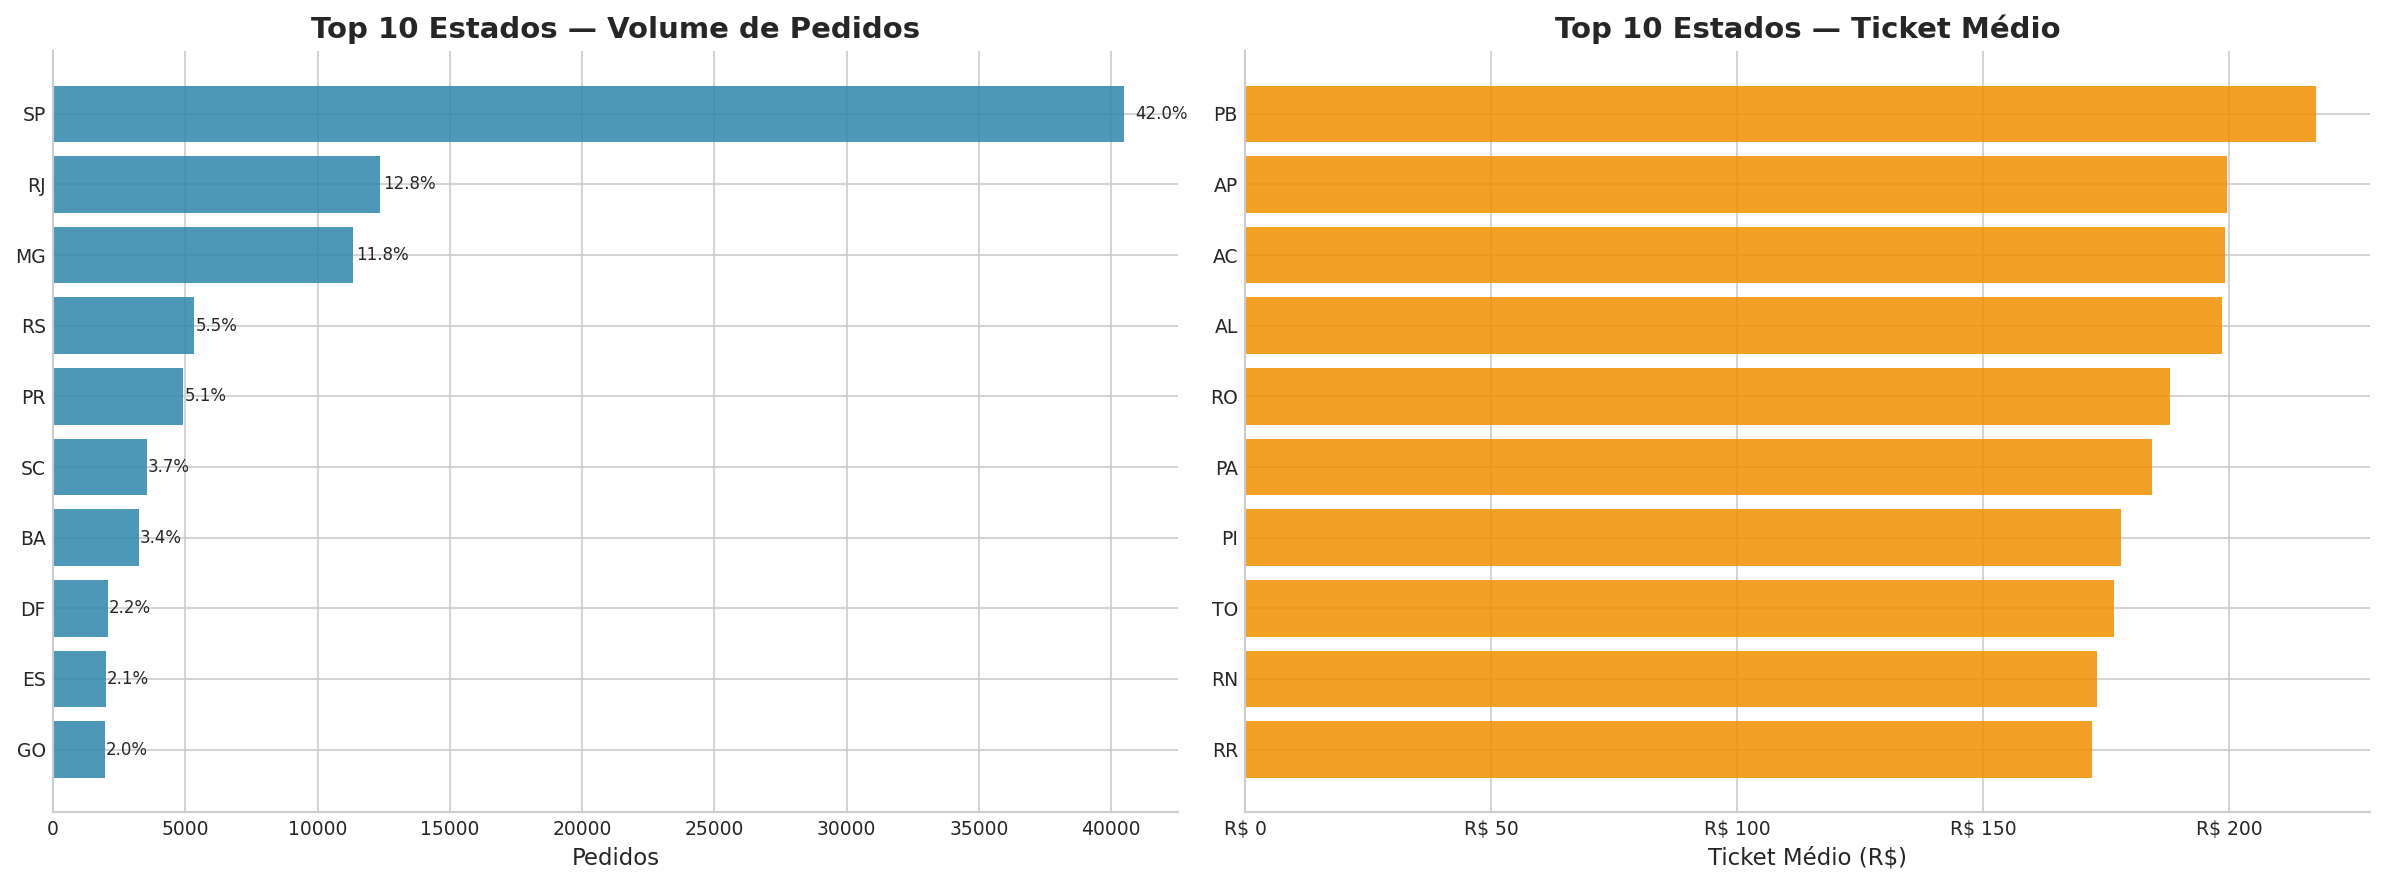

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

top10_states = state_stats.head(10)

# Pedidos por estado
axes[0].barh(top10_states['customer_state'], top10_states['pedidos'],
             color=COLORS['primary'], alpha=0.85)
axes[0].invert_yaxis()
axes[0].set_title('Top 10 Estados — Volume de Pedidos')
axes[0].set_xlabel('Pedidos')
for i, (_, row) in enumerate(top10_states.iterrows()):
    axes[0].text(row['pedidos'] * 1.01, i, f'{row["share_pct"]:.1f}%', va='center', fontsize=8)

# Ticket médio por estado
top10_ticket = state_stats.nlargest(10, 'ticket_medio')
axes[1].barh(top10_ticket['customer_state'], top10_ticket['ticket_medio'],
             color=COLORS['accent'], alpha=0.85)
axes[1].invert_yaxis()
axes[1].set_title('Top 10 Estados — Ticket Médio')
axes[1].set_xlabel('Ticket Médio (R$)')
axes[1].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'R$ {x:,.0f}'))

plt.tight_layout()
save_fig('04_estados')
plt.show()

  ✓ Figura salva: 04_mapa_estados.png


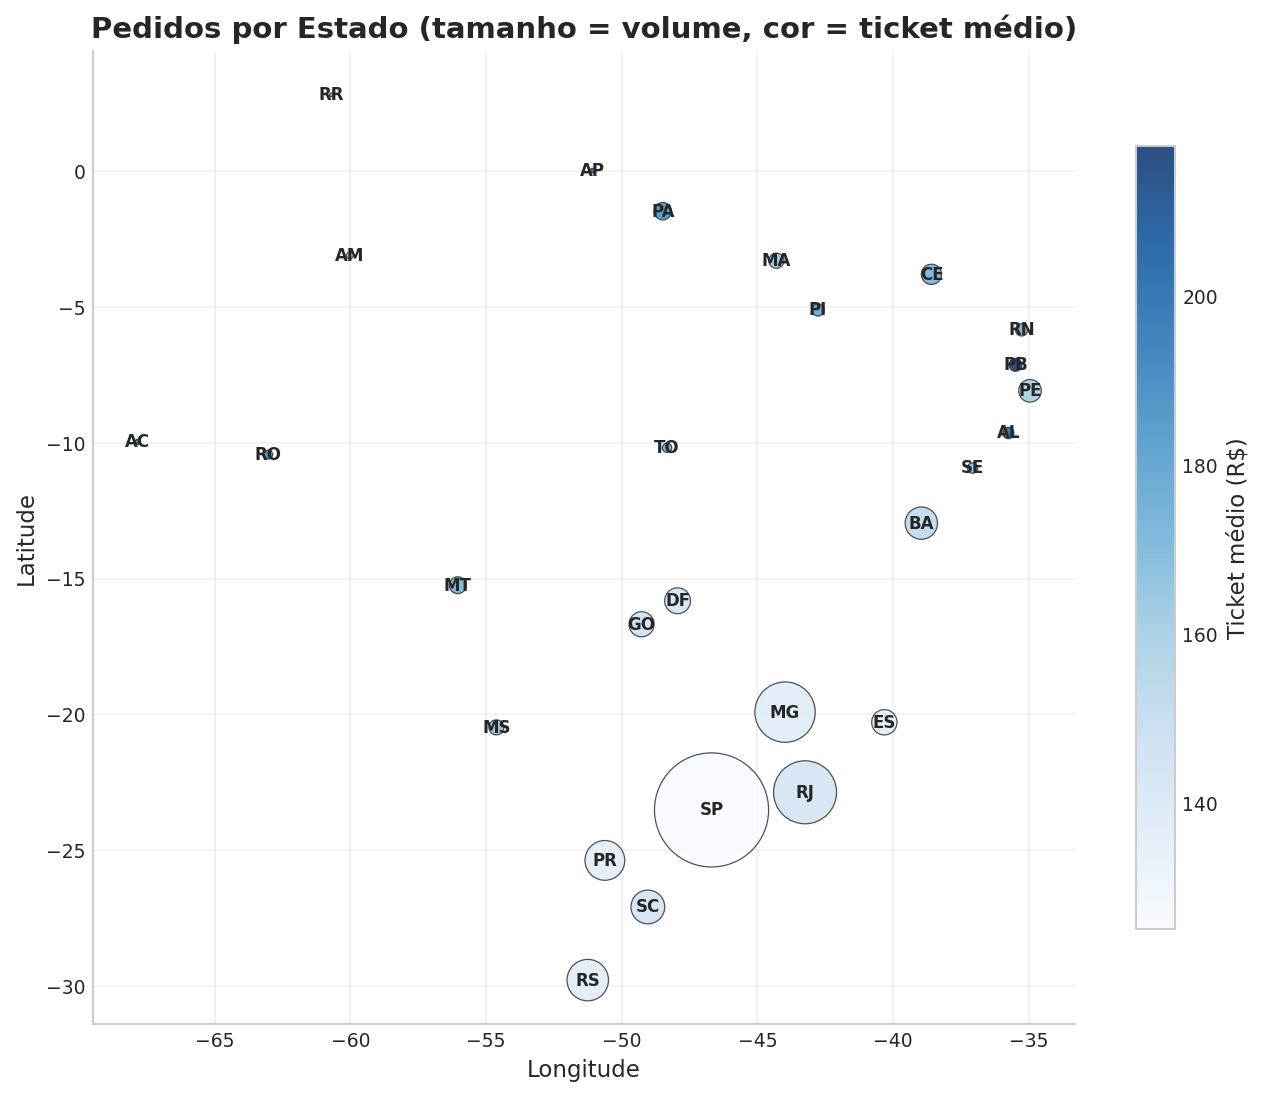

In [5]:
# Mapa de bolhas por estado
# O centro de cada estado vem da média das coordenadas do próprio dataset de geolocalização da Olist
from src.data_loader import load_raw_dataset

geo = load_raw_dataset('geolocation')
# Remove coordenadas fora do território brasileiro (há alguns pontos errados no dataset)
geo = geo[geo['geolocation_lat'].between(-34, 6) & geo['geolocation_lng'].between(-74, -34)]
centros = (
    geo.groupby('geolocation_state')[['geolocation_lat', 'geolocation_lng']]
    .median()
    .rename_axis('customer_state')
    .reset_index()
)

mapa = state_stats.merge(centros, on='customer_state', how='left')

fig, ax = plt.subplots(figsize=(9, 9))
sc = ax.scatter(
    mapa['geolocation_lng'], mapa['geolocation_lat'],
    s=mapa['pedidos'] / mapa['pedidos'].max() * 3000,
    c=mapa['ticket_medio'], cmap='Blues', edgecolor='#333333', linewidth=0.6, alpha=0.85,
)
for _, row in mapa.iterrows():
    ax.annotate(row['customer_state'], (row['geolocation_lng'], row['geolocation_lat']),
                ha='center', va='center', fontsize=8, fontweight='bold')
plt.colorbar(sc, ax=ax, shrink=0.6, label='Ticket médio (R$)')
ax.set_title('Pedidos por Estado (tamanho = volume, cor = ticket médio)')
ax.set_xlabel('Longitude')
ax.set_ylabel('Latitude')
ax.set_aspect('equal')
ax.grid(alpha=0.3)
plt.tight_layout()
save_fig('04_mapa_estados')
plt.show()

## 2. Padrão de Compra por Hora e Dia da Semana

  ✓ Figura salva: 04_heatmap_hora_dia.png


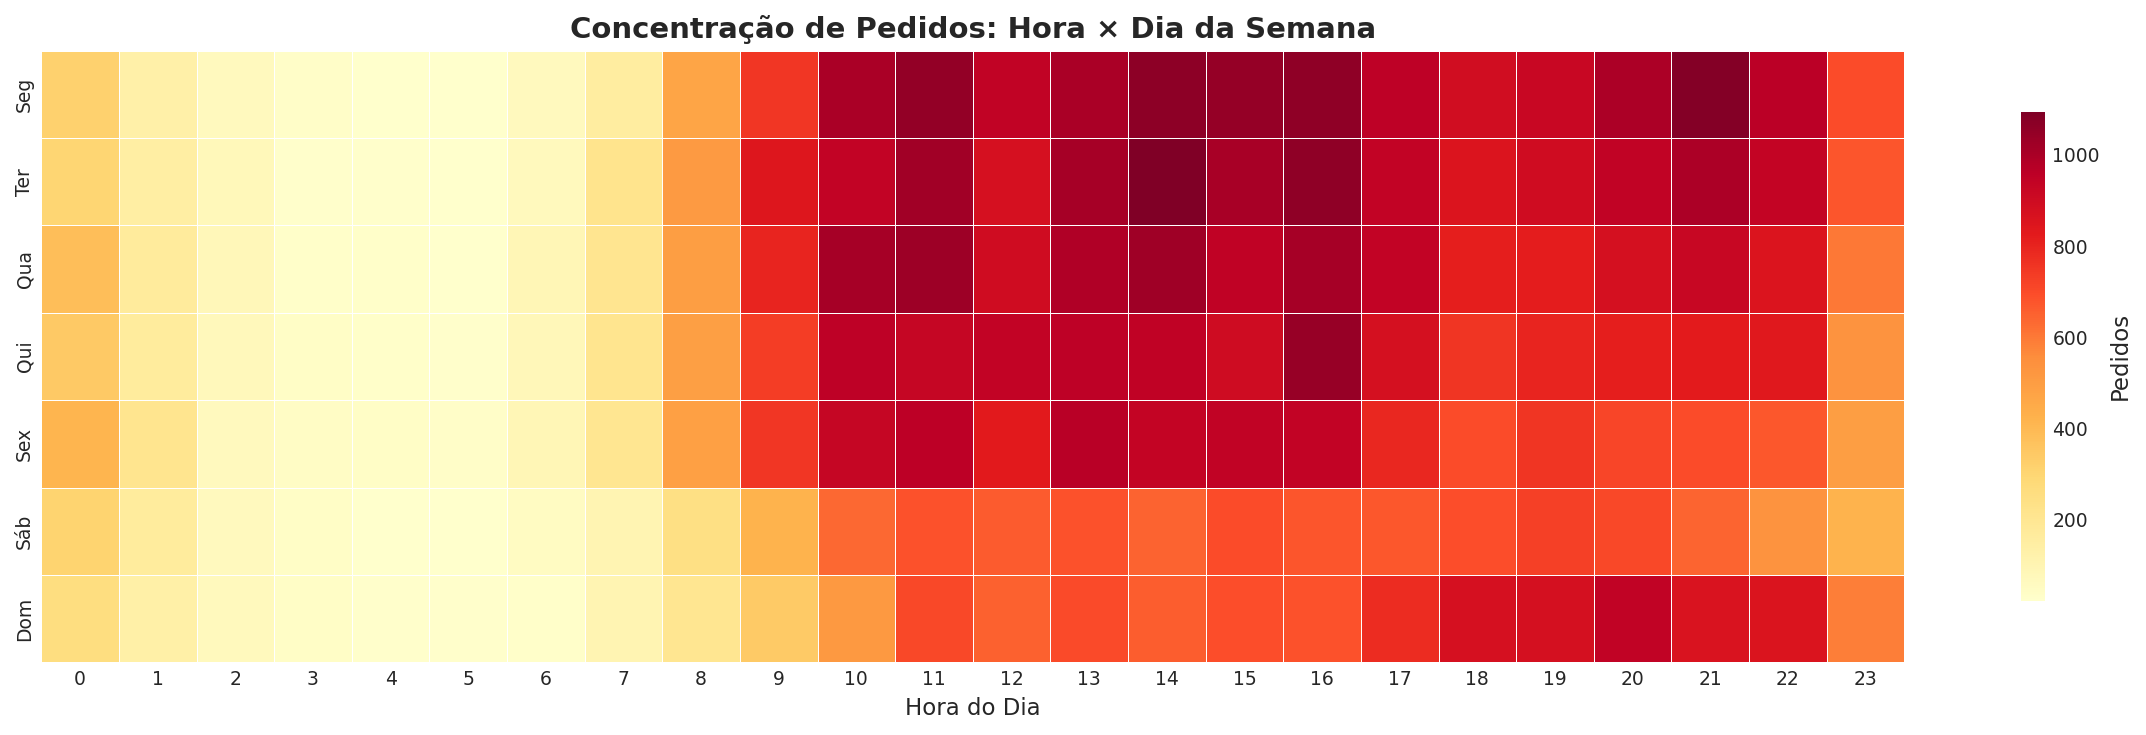

Combinação de maior volume: Ter, 14h


In [6]:
dias_ordem = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
dias_pt = ['Seg', 'Ter', 'Qua', 'Qui', 'Sex', 'Sáb', 'Dom']
dia_map = dict(zip(dias_ordem, dias_pt))

delivered['dia_semana_pt'] = delivered['purchase_day_of_week'].map(dia_map)

heatmap_data = (
    delivered
    .groupby(['purchase_day_of_week', 'purchase_hour'])['order_id']
    .count()
    .unstack(fill_value=0)
    .reindex(dias_ordem)
)
heatmap_data.index = dias_pt

fig, ax = plt.subplots(figsize=(16, 5))
sns.heatmap(
    heatmap_data,
    ax=ax,
    cmap='YlOrRd',
    linewidths=0.3,
    annot=False,
    cbar_kws={'shrink': 0.8, 'label': 'Pedidos'},
)
ax.set_title('Concentração de Pedidos: Hora × Dia da Semana', fontsize=14)
ax.set_xlabel('Hora do Dia')
ax.set_ylabel('')
plt.tight_layout()
save_fig('04_heatmap_hora_dia')
plt.show()

pico = heatmap_data.stack().idxmax()
print(f'Combinação de maior volume: {pico[0]}, {pico[1]}h')

## 3. Taxa de Recompra

In [7]:
# Contagem de pedidos por cliente único
pedidos_por_cliente = (
    delivered
    .groupby('customer_unique_id')['order_id']
    .count()
    .rename('n_pedidos')
)

total_clientes = len(pedidos_por_cliente)
recompradores = (pedidos_por_cliente > 1).sum()
taxa_recompra = recompradores / total_clientes

dist_pedidos = pedidos_por_cliente.value_counts().sort_index().head(10)

print(f'Total de clientes únicos: {total_clientes:,}')
print(f'Clientes com mais de 1 pedido: {recompradores:,} ({taxa_recompra:.1%})')
print(f'Máx. pedidos por cliente: {pedidos_por_cliente.max()}')
print()
print('Distribuição de pedidos por cliente:')
for n, count in dist_pedidos.items():
    print(f'  {n} pedido(s): {count:,} clientes ({count/total_clientes:.1%})')

Total de clientes únicos: 93,358
Clientes com mais de 1 pedido: 2,801 (3.0%)
Máx. pedidos por cliente: 15

Distribuição de pedidos por cliente:
  1 pedido(s): 90,557 clientes (97.0%)
  2 pedido(s): 2,573 clientes (2.8%)
  3 pedido(s): 181 clientes (0.2%)
  4 pedido(s): 28 clientes (0.0%)
  5 pedido(s): 9 clientes (0.0%)
  6 pedido(s): 5 clientes (0.0%)
  7 pedido(s): 3 clientes (0.0%)
  9 pedido(s): 1 clientes (0.0%)
  15 pedido(s): 1 clientes (0.0%)


  ✓ Figura salva: 04_recompra.png


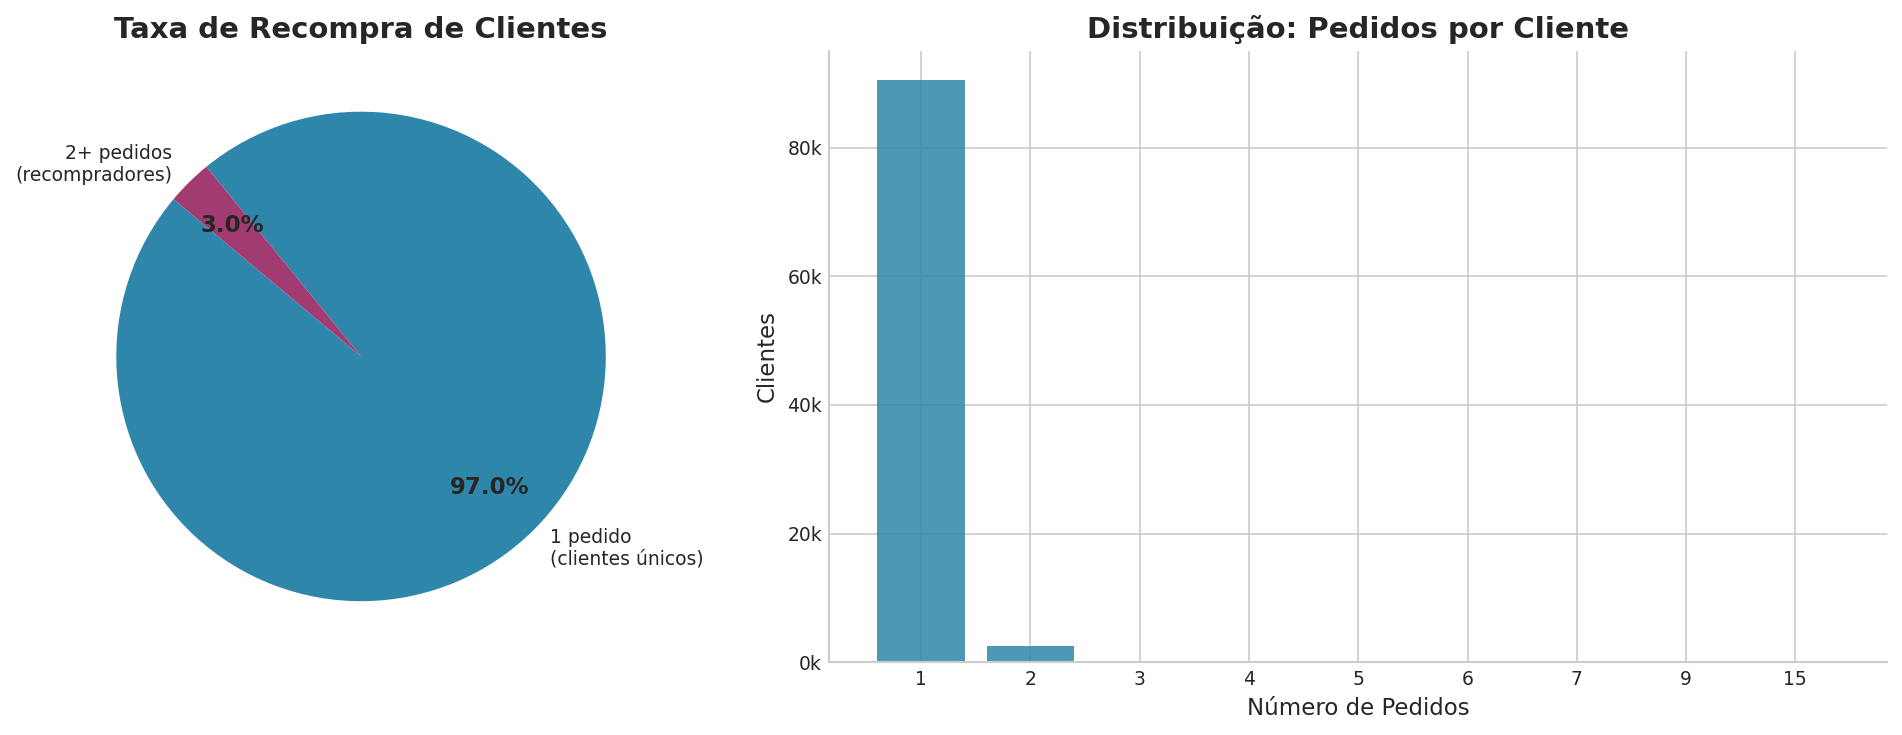

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Pizza: 1 vs 2+ pedidos
labels = ['1 pedido\n(clientes únicos)', '2+ pedidos\n(recompradores)']
sizes = [total_clientes - recompradores, recompradores]
colors_pie = [COLORS['primary'], COLORS['secondary']]
wedges, texts, autotexts = axes[0].pie(
    sizes, labels=labels, autopct='%1.1f%%',
    colors=colors_pie, startangle=140, pctdistance=0.75
)
for at in autotexts:
    at.set_fontsize(11)
    at.set_fontweight('bold')
axes[0].set_title('Taxa de Recompra de Clientes')

# Distribuição de pedidos por cliente
axes[1].bar(
    dist_pedidos.index.astype(str),
    dist_pedidos.values,
    color=COLORS['primary'], alpha=0.85
)
axes[1].set_title('Distribuição: Pedidos por Cliente')
axes[1].set_xlabel('Número de Pedidos')
axes[1].set_ylabel('Clientes')
axes[1].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e3:.0f}k'))

plt.tight_layout()
save_fig('04_recompra')
plt.show()

## 4. LTV Básico (Lifetime Value)

In [9]:
ltv = (
    delivered
    .groupby('customer_unique_id')
    .agg(
        n_pedidos=('order_id', 'count'),
        ltv=('revenue', 'sum'),
        primeiro_pedido=('order_purchase_timestamp', 'min'),
        ultimo_pedido=('order_purchase_timestamp', 'max'),
    )
    .reset_index()
)
ltv['ciclo_vida_dias'] = (ltv['ultimo_pedido'] - ltv['primeiro_pedido']).dt.days

print('Estatísticas de LTV por cliente único:')
print(f'  LTV médio: {format_brl(ltv["ltv"].mean())}')
print(f'  LTV mediana: {format_brl(ltv["ltv"].median())}')
print(f'  LTV total: {format_brl(ltv["ltv"].sum())}')
print(f'  LTV p90: {format_brl(ltv["ltv"].quantile(0.90))}')
print(f'  LTV p99: {format_brl(ltv["ltv"].quantile(0.99))}')

# Concentração de receita (Pareto)
ltv_sorted = ltv.sort_values('ltv', ascending=False).reset_index(drop=True)
ltv_sorted['ltv_cumulativo_pct'] = ltv_sorted['ltv'].cumsum() / ltv_sorted['ltv'].sum() * 100
ltv_sorted['clientes_pct'] = (ltv_sorted.index + 1) / len(ltv_sorted) * 100

pareto_20 = ltv_sorted.loc[ltv_sorted['clientes_pct'] <= 20, 'ltv_cumulativo_pct'].max()
print(f'\n  Os top 20% dos clientes representam {pareto_20:.1f}% da receita total (Pareto)')

Estatísticas de LTV por cliente único:
  LTV médio: R$ 141,62
  LTV mediana: R$ 89,73
  LTV total: R$ 13.221.498,11
  LTV p90: R$ 279,99
  LTV p99: R$ 1.004,99

  Os top 20% dos clientes representam 56.6% da receita total (Pareto)


  ✓ Figura salva: 04_ltv.png


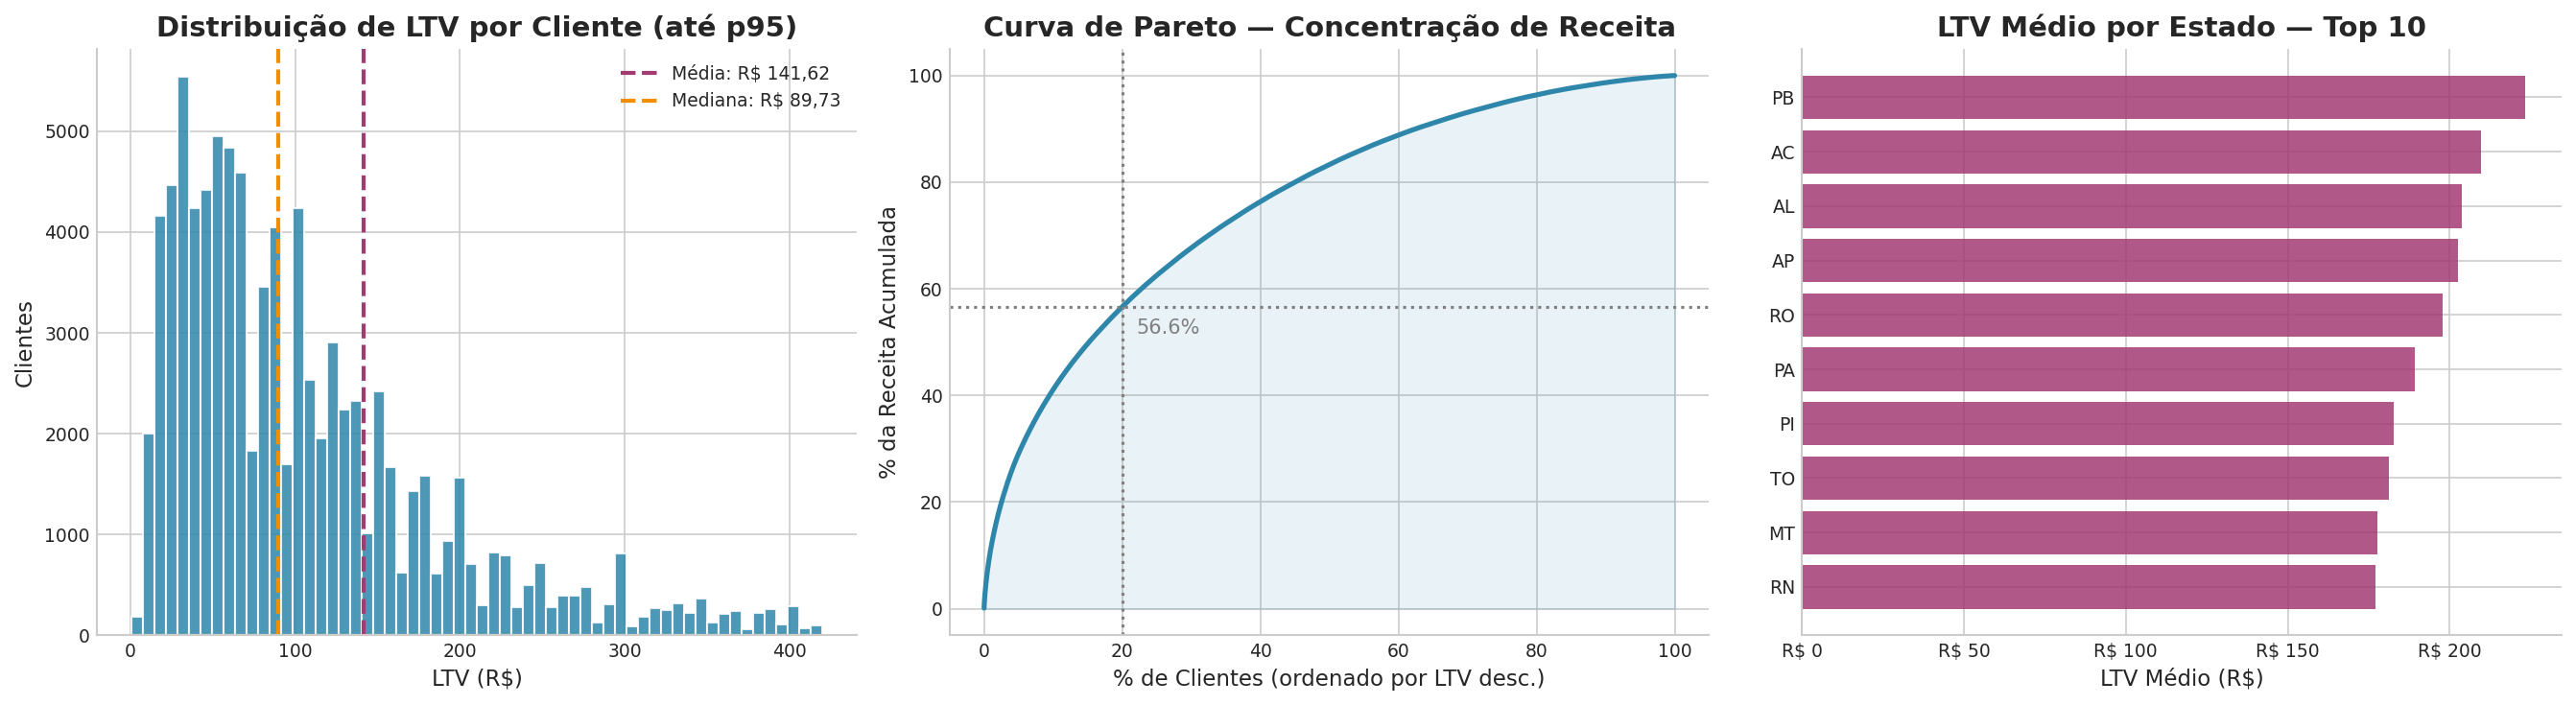

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Histograma de LTV
p95_ltv = ltv['ltv'].quantile(0.95)
axes[0].hist(ltv.loc[ltv['ltv'] <= p95_ltv, 'ltv'], bins=60,
             color=COLORS['primary'], alpha=0.85, edgecolor='white')
axes[0].axvline(ltv['ltv'].mean(), color=COLORS['secondary'], linestyle='--', linewidth=2,
                label=f'Média: {format_brl(ltv["ltv"].mean())}')
axes[0].axvline(ltv['ltv'].median(), color=COLORS['accent'], linestyle='--', linewidth=2,
                label=f'Mediana: {format_brl(ltv["ltv"].median())}')
axes[0].set_title('Distribuição de LTV por Cliente (até p95)')
axes[0].set_xlabel('LTV (R$)')
axes[0].set_ylabel('Clientes')
axes[0].legend()

# Curva de Pareto
axes[1].plot(ltv_sorted['clientes_pct'], ltv_sorted['ltv_cumulativo_pct'],
             color=COLORS['primary'], linewidth=2.5)
axes[1].axvline(20, color='gray', linestyle=':', linewidth=1.5)
axes[1].axhline(pareto_20, color='gray', linestyle=':', linewidth=1.5)
axes[1].fill_between(ltv_sorted['clientes_pct'], ltv_sorted['ltv_cumulativo_pct'],
                     alpha=0.1, color=COLORS['primary'])
axes[1].set_title('Curva de Pareto — Concentração de Receita')
axes[1].set_xlabel('% de Clientes (ordenado por LTV desc.)')
axes[1].set_ylabel('% da Receita Acumulada')
axes[1].text(22, pareto_20 - 5, f'{pareto_20:.1f}%', fontsize=10, color='gray')

# LTV médio por estado (top 10)
ltv_estado = (
    delivered
    .groupby(['customer_unique_id', 'customer_state'])['revenue']
    .sum()
    .reset_index()
    .groupby('customer_state')['revenue']
    .mean()
    .sort_values(ascending=False)
    .head(10)
)
axes[2].barh(ltv_estado.index, ltv_estado.values, color=COLORS['secondary'], alpha=0.85)
axes[2].invert_yaxis()
axes[2].set_title('LTV Médio por Estado — Top 10')
axes[2].set_xlabel('LTV Médio (R$)')
axes[2].xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'R$ {x:,.0f}'))

plt.tight_layout()
save_fig('04_ltv')
plt.show()

## 5. Cohort Mensal de Novos Clientes

  ✓ Figura salva: 04_novos_clientes.png


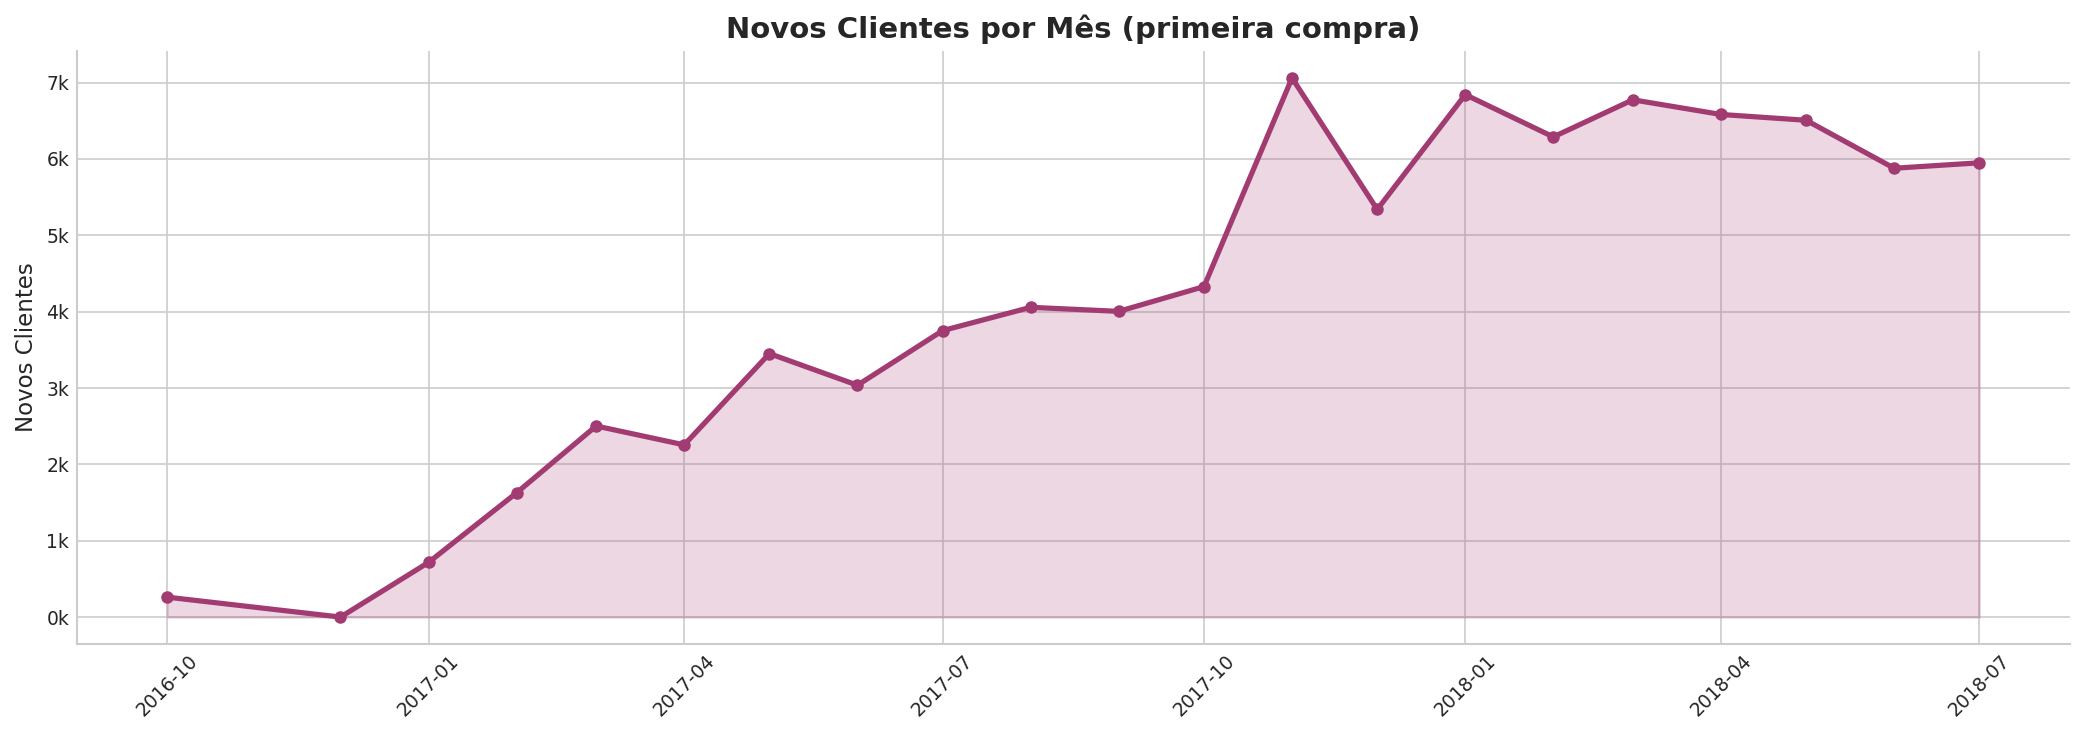

In [11]:
# Primeiro pedido de cada cliente
primeiro_pedido = (
    delivered
    .groupby('customer_unique_id')['order_purchase_timestamp']
    .min()
    .reset_index()
    .rename(columns={'order_purchase_timestamp': 'primeiro_pedido'})
)
primeiro_pedido['cohort_mes'] = primeiro_pedido['primeiro_pedido'].dt.to_period('M')

novos_por_mes = (
    primeiro_pedido
    .groupby('cohort_mes')['customer_unique_id']
    .count()
    .reset_index()
)
novos_por_mes['mes'] = novos_por_mes['cohort_mes'].dt.to_timestamp()
novos_por_mes = novos_por_mes.iloc[1:-1]  # Remove meses parciais

fig, ax = plt.subplots(figsize=(14, 5))
ax.fill_between(novos_por_mes['mes'], novos_por_mes['customer_unique_id'],
                alpha=0.2, color=COLORS['secondary'])
ax.plot(novos_por_mes['mes'], novos_por_mes['customer_unique_id'],
        color=COLORS['secondary'], linewidth=2.5, marker='o', markersize=5)
ax.set_title('Novos Clientes por Mês (primeira compra)')
ax.set_xlabel('')
ax.set_ylabel('Novos Clientes')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x/1e3:.0f}k'))
plt.xticks(rotation=45)
plt.tight_layout()
save_fig('04_novos_clientes')
plt.show()

## 6. Sumário e Insights

| Métrica | Valor |
|---------|-------|
| Clientes únicos (pedidos entregues) | 93.358 |
| Taxa de recompra | 3,0% (2.801 clientes com mais de 1 pedido) |
| Estado dominante | SP (42,0% dos pedidos), seguido de RJ (12,8%) e MG (11,8%) |
| LTV médio / mediana | R$ 141,62 / R$ 89,73 |
| Pareto | os 20% clientes de maior valor somam 56,6% da receita |
| Pico de compras | terça-feira às 14h |

### Observações importantes
- 97% dos clientes compraram uma única vez no período. Por isso o LTV é praticamente o valor da primeira compra, e qualquer segmentação vai depender muito mais de recência e valor do que de frequência.
- A concentração em SP, RJ e MG (dois terços dos pedidos) acompanha a população e a malha logística do Sudeste.
- A receita é concentrada, mas menos do que a regra 80/20 sugere: os top 20% ficam com 56,6%.

### Próximo Notebook
`05_segmentacao_rfm.ipynb` — segmentação formal dos clientes com K-Means (Recência, Frequência, Valor).